# 08 · Two final checks: what a pair is worth, and whether the engine is stable

**1. The measured value of a pair (no assumptions).** How much more gross profit does a paired order earn than a
half-order, and what is converting just 1% of half-orders worth? This anchors the business case in observed numbers
only, independent of any acceptance assumption.

**2. Stability over time.** If the engine is retrained on different months, do its suggestions change, and does
that cost money? This tests whether the engine is fitting real behaviour or noise, and how often Stories must refresh it.

**What we find**
- A paired order earns **$7.46** of gross profit vs **$4.48** for a drink-only and **$4.40** for a food-only order:
  about **+$3 per pair (+68%)**. The add-on itself earns $3.55 on average ($4.01 at Harbour, $2.85 at Garden).
- **Every 1% of half-orders turned into pairs is worth about $1,700 of gross profit a year** (~490 extra pairs ×
  the measured $3.55 an add-on earns; assumes a converted order adds a typical add-on and replaces no later purchase).
  The +68% gap is an association: paired orders are bigger in general, so only the add-on's own profit is counted. The ~$17k estimate in notebook 05 corresponds to converting roughly 9-10% of half-orders.
- Trained on January-March vs April-June, 66% of the 135 suggestions are identical, and the rest swap between
  near-equal options (Lemonade vs Peach Iced Tea). **Using a three-month-old playbook keeps 96% of the value.**
  A monthly refresh is more than enough.

In [1]:
# Setup: works in Google Colab, local Jupyter, and from the repo root
import os, sys, subprocess
REPO_URL = "https://github.com/mouhammed-soumaille/EECE-490-Hackathon.git"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/EECE-490-Hackathon"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/EECE-490-Hackathon"], check=True)
    os.chdir("/content/EECE-490-Hackathon")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from storiespair import data, models, engine as E, viz
viz.style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

lines = data.load_lines()
orders = data.build_orders(lines)
added = data.other_side_first_item(lines, orders)
ue = data.unit_economics(lines)
cfg = E.load_config()

## 1. What a pair is worth (measured)

In [2]:
comp = orders.groupby("composition").agg(orders=("gp", "size"), gross_profit_per_order=("gp", "mean"),
                                        revenue_per_order=("revenue", "mean"), lines_per_order=("n_lines", "mean"))
comp = comp.loc[["drink only", "food only", "drink + food"]]
single_gp = orders.loc[orders.composition != "drink + food", "gp"]
pair_gp = orders.loc[orders.composition == "drink + food", "gp"]
t = stats.ttest_ind(pair_gp, single_gp, equal_var=False)
print(f"Paired vs half-order gross profit: ${pair_gp.mean():.2f} vs ${single_gp.mean():.2f} "
      f"(+${pair_gp.mean() - single_gp.mean():.2f}, +{pair_gp.mean() / single_gp.mean() - 1:.0%}); Welch t-test p = {t.pvalue:.1e}")
comp.round(2)

Paired vs half-order gross profit: $7.46 vs $4.44 (+$3.02, +68%); Welch t-test p = 0.0e+00


,orders,gross_profit_per_order,revenue_per_order,lines_per_order
composition,,,,
drink only,13865,4.48,6.95,1.29
food only,10459,4.40,8.33,1.23
drink + food,9563,7.46,12.80,2.13


In [3]:
side_first = orders.set_index("transaction_id").first_side
l2 = lines.join(side_first.rename("trigger_side"), on="transaction_id")
paired_ids = orders.loc[orders.paired, "transaction_id"]
addon_gp = l2[(l2.side != l2.trigger_side) & l2.transaction_id.isin(paired_ids)].groupby("transaction_id").line_gp.sum()
by_branch = orders[orders.paired].join(addon_gp.rename("addon_gp"), on="transaction_id").groupby("branch").addon_gp.mean()
annual_orders = len(orders) * 365 / orders.day.nunique()
half_share = (orders.composition != "drink + food").mean()
per_point = annual_orders * half_share * 0.01 * addon_gp.mean()
print(f"Gross profit of the add-on itself: ${addon_gp.mean():.2f} on average")
print(by_branch.round(2).to_string())
print(f"\nHalf-orders a year: {annual_orders * half_share:,.0f}. Converting 1% of them = {annual_orders * half_share * 0.01:,.0f} "
      f"extra pairs = ${per_point:,.0f} of gross profit a year.")
print(f"The notebook-05 base case (~$16.8k) corresponds to converting about {16811 / per_point:.1f}% of half-orders.")

Gross profit of the add-on itself: $3.55 on average
branch
Garden     2.85
Harbour    4.01
Uptown     3.62

Half-orders a year: 49,051. Converting 1% of them = 491 extra pairs = $1,742 of gross profit a year.
The notebook-05 base case (~$16.8k) corresponds to converting about 9.7% of half-orders.


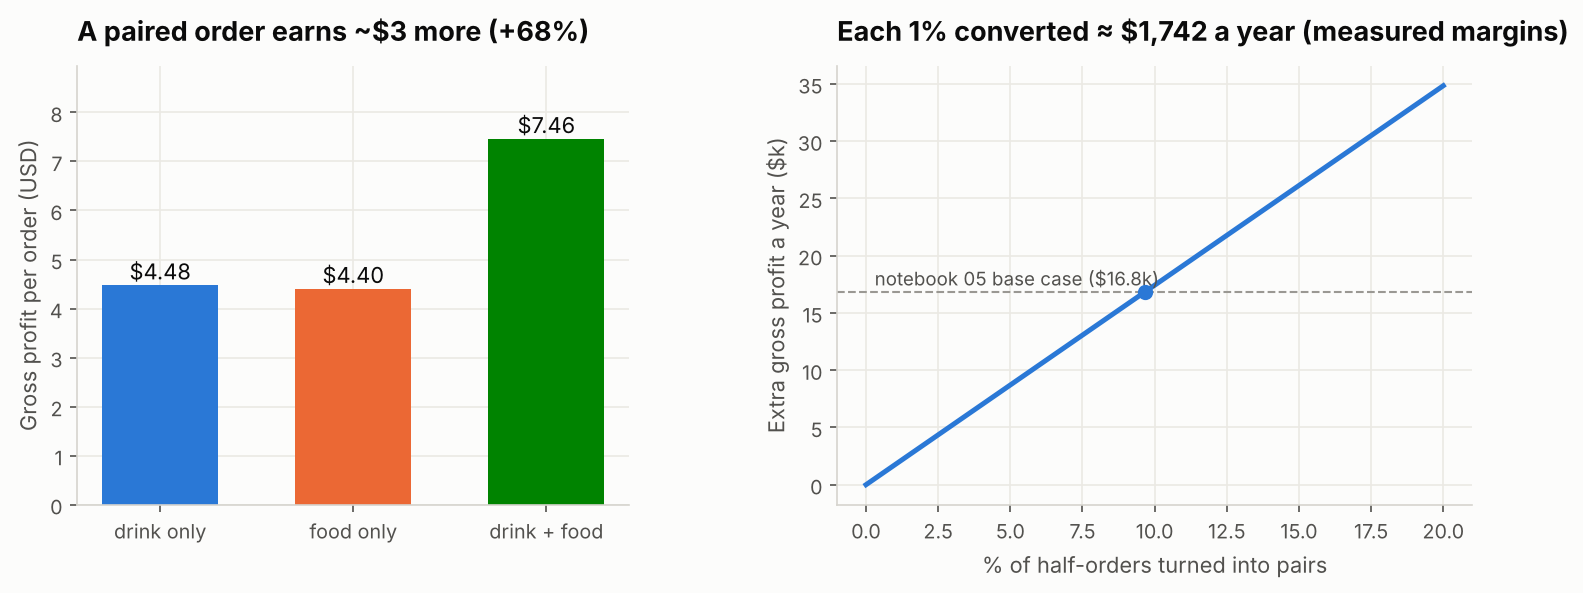

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"wspace": 0.35, "width_ratios": [1, 1.15]})
ax = axes[0]
vals = comp.gross_profit_per_order
cols = [viz.BLUE, viz.ORANGE, viz.GREEN]
ax.bar(range(3), vals.values, color=cols, width=0.6)
for i, v in enumerate(vals.values):
    ax.text(i, v + 0.12, f"${v:.2f}", ha="center", fontsize=10.5, color=viz.INK)
ax.set_xticks(range(3), vals.index)
ax.set_ylabel("Gross profit per order (USD)")
ax.set_title("A paired order earns ~$3 more (+68%)")
ax.set_ylim(0, vals.max() * 1.2)
ax = axes[1]
pts = np.arange(0, 21, 1)
ax.plot(pts, pts * per_point / 1000, color=viz.BLUE, lw=2.4)
ax.axhline(16.8, color=viz.GREY, ls="--", lw=1)
ax.text(0.3, 17.4, "notebook 05 base case ($16.8k)", fontsize=9, color=viz.INK_2)
ax.scatter([16811 / per_point], [16.8], color=viz.BLUE, s=40, zorder=3)
ax.set_xlabel("% of half-orders turned into pairs")
ax.set_ylabel("Extra gross profit a year ($k)")
ax.set_title(f"Each 1% converted ≈ ${per_point:,.0f} a year (measured margins)")
viz.savefig(fig, "08_value_of_a_pair")
plt.show()

## 2. Is the engine stable over time?

Retrain the measured parts (who pairs, which category, item shares) on two separate quarters and compare the
135-row playbooks. Then score the January-March playbook with the April-June engine: how much value does an
out-of-date playbook keep?

In [5]:
def engine_for(months):
    pm = models.PairModels.fit(orders, lines, added, months=months)
    return E.PairEngine(pm, ue, cfg["compatibility"], E.Assumptions.from_config(cfg), E.Guardrails.from_config(cfg))

e_q1, e_q2, e_all = engine_for((1, 2, 3)), engine_for((4, 5, 6)), engine_for((1, 2, 3, 4, 5))
pb_q1 = e_q1.playbook().set_index(["branch", "first_item"]).suggest
pb_q2 = e_q2.playbook().set_index(["branch", "first_item"]).suggest
pb_all = e_all.playbook().set_index(["branch", "first_item"]).suggest
agree = pd.DataFrame({"comparison": ["Jan-Mar vs Apr-Jun", "Jan-Mar vs Jan-May (deployed)", "Apr-Jun vs Jan-May (deployed)"],
                      "identical suggestions": [(pb_q1 == pb_q2).mean(), (pb_q1 == pb_all).mean(), (pb_q2 == pb_all).mean()]})
agree.style.format({"identical suggestions": "{:.0%}"})

,comparison,identical suggestions
0,Jan-Mar vs Apr-Jun,66%
1,Jan-Mar vs Jan-May (deployed),76%
2,Apr-Jun vs Jan-May (deployed),84%


In [6]:
weights = orders[orders.month >= 4].groupby(["branch", "first_product"]).size()
best_total = old_total = 0.0
for (b, f), old in pb_q1.items():
    r = e_q2.recommend(b, "2026-06-03 13:00", [f])
    c = r["candidates"]
    gains = c[(c.discount == 0) & c.allowed].set_index("item").expected_gain
    best = r["expected_gain"] if r["offer"] else 0.0
    kept = gains.get(old, 0.0) if old != "(no offer)" else 0.0
    n = weights.get((b, f), 0)
    best_total += best * n
    old_total += kept * n
kept_share = old_total / best_total
print(f"Value kept by a three-month-old playbook (scored with the April-June engine): {kept_share:.1%}")
changes = pd.DataFrame({"Jan-Mar": pb_q1, "Apr-Jun": pb_q2})[pb_q1 != pb_q2]
changes.groupby(["Jan-Mar", "Apr-Jun"]).size().sort_values(ascending=False).rename("first items").head(8).reset_index()

Value kept by a three-month-old playbook (scored with the April-June engine): 96.4%


,Jan-Mar,Apr-Jun,first items
0,Egg Sandwich,Chicken Pesto Sandwich,10
1,Lemonade,Fresh Orange Juice,8
2,Lemonade,Peach Iced Tea,7
3,Iced Matcha,Iced Latte,6
4,Peach Iced Tea,Fresh Orange Juice,6
5,Egg Sandwich,Butter Croissant,5
6,Egg Sandwich,Halloumi Wrap,3
7,Cheesecake Slice,Butter Croissant,1


The suggestions that change swap between options of almost equal value (a lemonade for a peach iced tea, an egg
sandwich for a halloumi wrap), which is why an out-of-date playbook still keeps about 96% of the value. The engine
is tracking stable behaviour, not noise. **A monthly refresh is enough**; v2's nightly learning keeps it current anyway.

In [7]:
summary = pd.DataFrame([
    {"check": "Gross profit per paired order", "value": f"${pair_gp.mean():.2f}"},
    {"check": "Gross profit per half-order", "value": f"${single_gp.mean():.2f}"},
    {"check": "Average gross profit of the add-on", "value": f"${addon_gp.mean():.2f}"},
    {"check": "Value of converting 1% of half-orders", "value": f"${per_point:,.0f} / yr"},
    {"check": "Identical suggestions, Jan-Mar vs Apr-Jun", "value": f"{(pb_q1 == pb_q2).mean():.0%}"},
    {"check": "Value kept by a 3-month-old playbook", "value": f"{kept_share:.1%}"},
])
viz.savetable(summary, "08_value_and_stability")
summary

,check,value
0,Gross profit per paired order,$7.46
1,Gross profit per half-order,$4.44
2,Average gross profit of the add-on,$3.55
3,Value of converting 1% of half-orders,"$1,742 / yr"
4,"Identical suggestions, Jan-Mar vs Apr-Jun",66%
5,Value kept by a 3-month-old playbook,96.4%
